# MCMC for the identification of uncertain paramters in MEMS

In [16]:
import numpy as np
from scipy.integrate import solve_ivp
import matplotlib.pyplot as plt

# parameters
M = 5.6e-09             # shuttle mass [kg]
Q = 0.7                 # Q factor
eps = 8.854e-12         # [F/m] vacuum permittivity
NA = 30e-6*200e-6 * 10  # [m^2] area of one electrode plate time the number of capacitors
g = 2e-6                # [m] gap of capacitor
tildef = 1200           # [Hz] frequency for imposed voltage V


## Definition of spring stiffness and damping as a function of u

In [17]:
def generate_KC(u): # u: double-sided overetch (um) 

    L = 200e-6              # [m] length of the beam
    E = 160e9               # [Pa] Young's Module of long beam
    b = (2.8 - u)*1e-6      # [m] width of the beam
    h = 30e-6               # [m] height of the beam
    I = h*b**3/12           # [m^4] second moment of area
    K = 2/6 * 12*E*I/L**3   # [N/m] stiffness of two springs
    eigen = np.sqrt(K/M)    # eigen frequency
    C = eigen/Q*M           # damping cufficient

    return K, C
    

## Definition of the dynamic model  

$$ m\ddot x + c(u)\dot x + k(u)x = \frac{N}{2}\dfrac{\varepsilon A}{(g-x)^2}V^2(t) $$

$$
\frac{d}{dt}
\begin{bmatrix}
x\\
\dot{x}
\end{bmatrix}
=
\begin{bmatrix}
0 & 1\\
-\dfrac{k}{m} & -\dfrac{c}{m}
\end{bmatrix}
\begin{bmatrix}
x\\
\dot{x}
\end{bmatrix}
+
\begin{bmatrix}
0\\
\dfrac{N}{2m}\dfrac{\varepsilon A}{(g-x)^2}V^2(t)
\end{bmatrix}
$$

The imposed voltage $V(t)$ is sinusoidal with frequency $\tilde{f}/2$ and remains active for one period. $V^2(t)$ has indeed frequency $\tilde{f}$:
$$
V(t)=1.2\,\sin(\pi\tilde{f} t), \quad
V^2(t)=\frac{1.2^2}{2}\,\bigl(1-\cos(2\pi\tilde{f}t)\bigr)
\qquad t<2/\tilde{f}
$$

The model will be integrated numerically with Runge Kutta RK45

In [18]:
def Analytical_Model(u):  # u: double-sided overetch (um) 

    # parameters
    K,C = generate_KC(u)    # stiffness [N/m] and C

    # Initial condition
    x0 = [0.0,              # initial displacement [m]
          0.0]              # initial velocity [m/s]

    # time setting
    dt = 5e-6               # time step [s]
    t_0 = 0                 # initial time [s]
    step = 600              # number of steps
    t_span = [t_0, step*dt] # time span [s]
    t_eval=np.arange(t_0, step*dt, dt)

    # RK45 solution
    def ode(t, state, *args):  
        x, dx = state
        K, M, C, eps, NA, g, tildef = args
        V = 1.2 * np.sin(tildef*np.pi*t) * (t<2/tildef)  # voltage [V]
        ddx = -K/M*x - C/M*dx + 1/2*eps*NA/M/(g-x)**2*V**2
        return [dx, ddx]

    sol = solve_ivp(ode, t_span, x0, args=(K, M, C, eps, NA, g, tildef), t_eval=t_eval)
    
    return sol.y[0]  # returns the displacement
    

**Comments**

`solve_ivp` numerically integrates the ODE from the time range in `t_span`, starting from the initial state `x0`. In this notebook, `x0 = [0, 0]` means the mass starts with zero displacement and zero velocity.

The default integration method is RK45. It chooses internal time steps adaptively to estimate and control numerical error. `t_eval` specifies the times at which we want the returned solution recorded; it does not force RK45 to take only those internal steps.

`sol.y[0]` is the displacement at each requested time. `sol.y[1]` would be the velocity.


## Generation of synthetic noisy measurements

Synthetic data are obtained:
- integrating the model numerically with RK45 algorithm with the correct value of u 
- adding Gaussian noise $X\sim\mathcal{N}(0,\sigma_{\text{noise}}^2)$  
- Gaussian noise can be generated from $X=\sigma_{\text{noise}} Z$, where $Z$ is a *standard* normal random variable $Z\sim\mathcal{N}(0,1)$


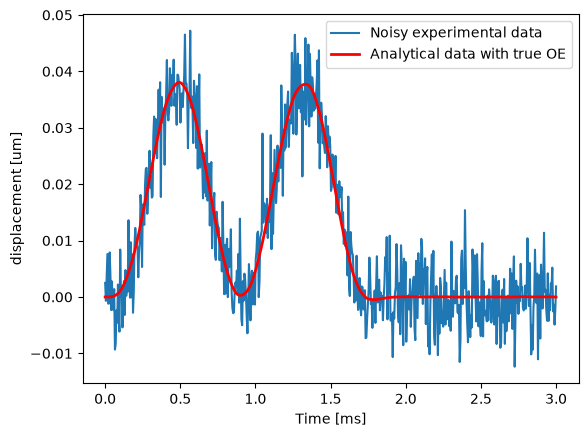

In [19]:
x_true = np.array(0.45)      # real value of u
y_true = Analytical_Model(x_true)  # computes the time history of displacements for real value of u
nstep = len(y_true)

# corrupts data by adding Gaussian noise to the true data
sigma_noise = .5e-8 
np.random.seed(42)
y_observed = y_true + sigma_noise * np.random.randn(nstep)

# plot readout signal
t = np.linspace(0, 5e-6*nstep, nstep)
plt.figure()
plt.plot(t*1000, y_observed*1e6,label='Noisy experimental data')
plt.plot(t*1000, y_true*1e6,label='Analytical data with true OE', color="red", linewidth="2")
plt.legend()
plt.xlabel('Time [ms]')
plt.ylabel('displacement [um]')
plt.show()


# Bayesian Inference

Bayes' rule gives the posterior density of the unknown parameter $u$:

$$
p(u\mid\mathbf{y})
=
\frac{p(\mathbf{y}\mid u)\,p(u)}{p(\mathbf{y})}
\propto p(\mathbf{y}\mid u)\,p(u),
$$

where $p(u)$ is the prior for the overetch, $p(\mathbf{y}\mid u)$ is the likelihood, and
$p(\mathbf{y})$ is a normalization factor independent of $u$.


## Prior definition

In this example, the prior for the overetch is Gaussian: 
$u\sim\mathcal{N}(\mu_{\mathrm{prior}},\sigma_{\mathrm{prior}}^2)$

It is convenient to work with logarithms: the logarithm turns products
into sums, and avoids numerical difficulties with very small densities.
Taking the logarithm of the prior and likelihood, and omitting terms
independent of $u$, gives

$$
\log p(u)
=
-\frac{1}{2}
\left(\frac{u-\mu_{\mathrm{prior}}}{\sigma_{\mathrm{prior}}}\right)^2
+\text{constant},
$$


In [20]:
prior_mean = 0.35
prior_std = 0.07

# Logarithm of the Gaussian prior, apart from additive constants.
def log_prior(x):

    return -0.5 * ((x - prior_mean) / prior_std)**2


## Likelihood definition

Let $\mathcal{M}_i(u)$ is the model prediction at the $i$th time step and $y_i$ the measurement.

We assume measurements are equal to the predictions plus independent Gaussian
errors:
$$
y_i=\mathcal{M}_i(u)+\varepsilon_i,
\qquad
\varepsilon_i\overset{\mathrm{i.i.d.}}{\sim}
\mathcal{N}(0,\sigma_{\mathrm{noise}}^2),
$$
The independence assumption means that the likelihood of all measurements
is the product of their individual Gaussian densities:
$$
p(\mathbf{y}\mid u)
=
\prod_{i=1}^{N}
\frac{1}{\sqrt{2\pi}\,\sigma_{\mathrm{noise}}}
\exp\!\Bigl[
-\frac{(y_i-\mathcal{M}_i(u))^2}
{2\sigma_{\mathrm{noise}}^2}
\Bigr].
$$

It is convenient to work with logarithms: the logarithm turns products into sums, and avoids
numerical difficulties with very small densitie. Taking the logarithm
$$\log p(\mathbf{y}\mid u)
=
-\frac{1}{2\sigma_{\mathrm{noise}}^2}
\sum_{i=1}^{N}\bigl(y_i-\mathcal{M}_i(u)\bigr)^2
+\text{constant}.
$$



In [21]:
def log_likelihood(x):
    
    residual = y_observed - Analytical_Model(x)

    return -0.5 * np.sum(residual**2) / sigma_noise**2


## Posterior definition

Therefore, the log-posterior, up to an additive constant, is
$$
\log p(u\mid\mathbf{y})
=
\log p(u)+\log p(\mathbf{y}\mid u)+\text{constant}.
$$

In [22]:
def log_posterior(x):

    return log_prior(x) + log_likelihood(x)


# Metropolis algorithm 

In [23]:
nchains = 2 # number of chains that will be computed

MCMC_SETTINGS = {
    'N': 1000,      # number of production samples
    'Nb': 500,      # number of burn-in samples
    'Nt': 1         # thinning factor: 1 = no thinning
}

# Gaussian random-walk proposal standard deviation
proposal_std = 0.01


## Metropolis with Gaussian random-walk proposal

For every step, given the current state $u_s$

- Set a proposal    $u'  = u_s + \varepsilon$, with $\varepsilon\sim \mathcal{N}(0,\sigma_{\text{proposal}})$
- Compute the acceptance ratio
 $$
   r =\frac{p(\mathbf{y}\mid u')p(u')}{p(\mathbf{y}\mid u_s)p(u_s)} 
 \quad   \rightarrow \quad
 \log r =\log p(\mathbf{y}\mid u')+\log p(u')-\log p(\mathbf{y}\mid u_s)-\log p(u_s)
    $$
- Generate $u \sim \mathcal{U}(0,1)$.

     - **if**  $ \log u < \alpha= \min(0,\log r) $   **then**
         $ u_{s+1}  \gets u'$
     - **else**
         $u_{s+1} \gets u_s$

The logarithm is strictly increasing, so using the log-posterior preserves
comparisons between posterior values. 
Additive constants independent of $u$ cancel in this difference, so the
Gaussian normalization factors can be omitted.


In [24]:
def metropolis(u0, N, Nb, proposal_std):

    # total number of MCMC iterations
    N_total = Nb + N

    # storage
    chain = np.zeros(N_total + 1)
    chain[0] = u0

    # evaluate posterior at initial point
    log_post_current = log_posterior(u0)

    accepted = 0

    for k in range(N_total):

        u_current = chain[k]

        # Gaussian random-walk proposal
        u_proposed = u_current + proposal_std * np.random.randn()

        # Posterior at proposed point
        log_post_proposed = log_posterior(u_proposed)

        # Metropolis acceptance probability
        log_r = log_post_proposed - log_post_current

        # accept if log(U) < log(r) with U ~ Uniform(0,1) 
        if np.log(np.random.rand()) < min(0.0, log_r):

            chain[k+1] = u_proposed
            log_post_current = log_post_proposed
            accepted += 1

        else:

            chain[k+1] = u_current

    acceptance_rate = accepted / N_total
    
    chain = chain[1:] # remove initial value
    chain = chain[Nb:] # remove burn-in
    chain = chain[::MCMC_SETTINGS['Nt']]  # thinning 

    return chain, acceptance_rate
    

Launches `nchains` with $u$ initialised in the range $[0.2:0.5]$

In [25]:
initial_guesses = np.linspace(0.20, 0.50, nchains)

print(f"True value: {x_true}")
print(f"Starting points: {initial_guesses}")

# ============================================================
# RUN CHAINS
# ============================================================

samples_mh = []

for i, u0 in enumerate(initial_guesses):

    samples, acceptance_rate = metropolis(
        u0=u0,
        N=MCMC_SETTINGS['N'],
        Nb=MCMC_SETTINGS['Nb'],
        proposal_std=proposal_std
    )

    samples_mh.append(samples)

    print(
        f"Chain {i+1}: "
        f"acceptance rate = {acceptance_rate:.3f}, "
        f"mean = {np.mean(samples):.5f}, "
        f"std = {np.std(samples):.5f}"
    )

True value: 0.45
Starting points: [0.2 0.5]
Chain 1: acceptance rate = 0.641, mean = 0.45075, std = 0.00916
Chain 2: acceptance rate = 0.674, mean = 0.45031, std = 0.00902


## Final operations

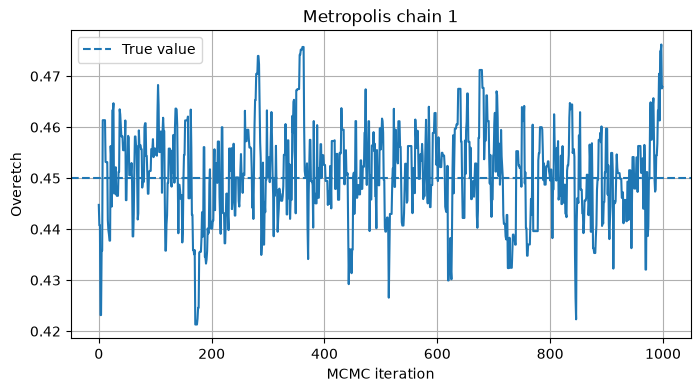

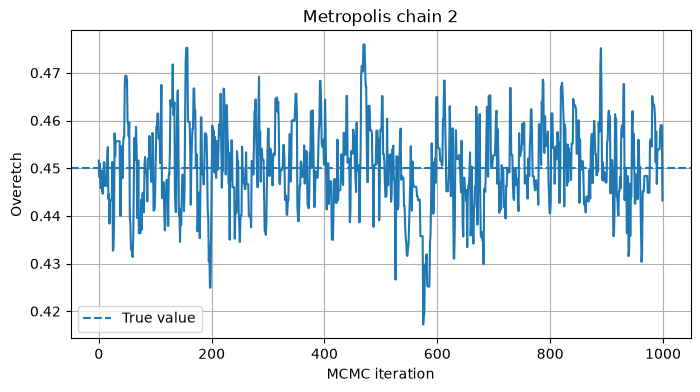

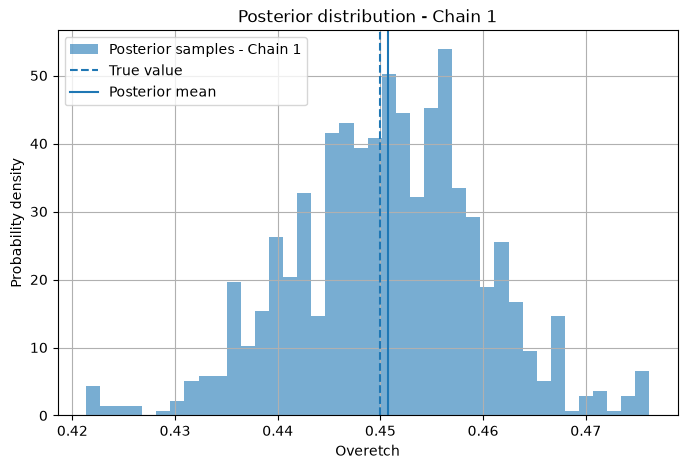

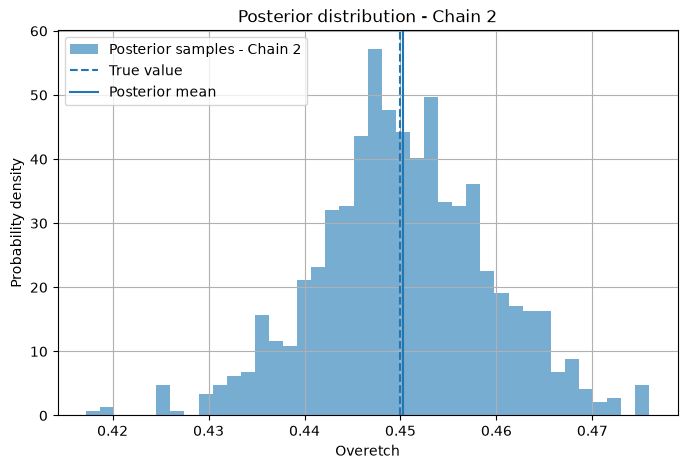

In [26]:

# Plots chains

for i in range(nchains):

    plt.figure(figsize=(8, 4))
    plt.plot(samples_mh[i])

    plt.axhline(
        x_true,
        linestyle='--',
        label='True value'
    )

    plt.xlabel('MCMC iteration')
    plt.ylabel('Overetch')
    plt.title(f'Metropolis chain {i+1}')
    plt.legend()
    plt.grid()

    plt.show()    
   

# Plots posterior distributions

for i in range(nchains):

    posterior_mean = np.mean(samples_mh[i])
    posterior_variance = np.var(samples_mh[i], ddof=1)

    plt.figure(figsize=(8, 5))

    plt.hist(
        samples_mh[i],
        bins=40,
        density=True,
        alpha=0.6,
        label=f'Posterior samples - Chain {i+1}'
    )

    plt.axvline(
        x_true,
        linestyle='--',
        label='True value'
    )

    plt.axvline(
        posterior_mean,
        linestyle='-',
        label='Posterior mean'
    )

    plt.xlabel('Overetch')
    plt.ylabel('Probability density')
    plt.title(f'Posterior distribution - Chain {i+1}')
    plt.legend()
    plt.grid()

    plt.show()